<a href="https://colab.research.google.com/github/sadeembader/Mining_project/blob/main/Reports/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# [1] Problem

The goal of this project is to analyze traffic accident data and identify patterns related to accident occurrence.


We chose this topic because traffic accidents are a major safety issue that affects individuals and transportation systems.


Analyzing traffic accident data can help identify important factors related to accidents and improve the understanding of accident patterns.


By applying classification and clustering techniques, this project provides a practical application of data mining to extract valuable information and support data-driven decisions for improving traffic safety.

# [2] Data Mining Task

For the classification task, the objective is to predict the severity of a traffic accident using techniques based on factors such as weather conditions, road characteristics, traffic conditions, and other accident related features. The target class attribute is Accident_Severity, which represents the severity level of a traffic accident.


For the clustering task, the objective is to group similar traffic situations based on their shared characteristics. This can help identify common traffic-condition patterns and potentially reveal groups associated with different levels of accident risk.

# [3] Data

## Importing Libraries

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import MinMaxScaler

## Dataset Source


[Accident Severity Dataset Link](https://www.kaggle.com/datasets/denkuznetz/traffic-accident-prediction)




## Dataset Description

In [ ]:


df = pd.read_csv('https://raw.githubusercontent.com/sadeembader/Mining_project/refs/heads/main/Dataset/Raw_dataset.csv')

print("Number of attributes :", df.shape[1])
print("\nData types of attributes:")
print(df.dtypes)

print("\nNumber of objects :", df.shape[0])

class_column = 'Accident_Severity'
print(f"\nClass attribute '{class_column}' with its values and count:")
print(df[class_column].value_counts())

print("\nSample of the raw dataset:")
print(df.head())

Number of attributes : 14

Data types of attributes:
Weather                  object
Road_Type                object
Time_of_Day              object
Traffic_Density         float64
Speed_Limit             float64
Number_of_Vehicles      float64
Driver_Alcohol          float64
Accident_Severity        object
Road_Condition           object
Vehicle_Type             object
Driver_Age              float64
Driver_Experience       float64
Road_Light_Condition     object
Accident                float64
dtype: object

Number of objects : 840

Class attribute 'Accident_Severity' with its values and count:
Accident_Severity
Low         478
Moderate    241
High         79
Name: count, dtype: int64

Sample of the raw dataset:
  Weather   Road_Type Time_of_Day  Traffic_Density  Speed_Limit  \
0   Rainy   City Road     Morning              1.0        100.0   
1   Clear  Rural Road       Night              NaN        120.0   
2   Rainy     Highway     Evening              1.0         60.0   
3   Clea

In [ ]:
print(df)

    Weather   Road_Type Time_of_Day  Traffic_Density  Speed_Limit  \
0     Rainy   City Road     Morning              1.0        100.0   
1     Clear  Rural Road       Night              NaN        120.0   
2     Rainy     Highway     Evening              1.0         60.0   
3     Clear   City Road   Afternoon              2.0         60.0   
4     Rainy     Highway     Morning              1.0        195.0   
..      ...         ...         ...              ...          ...   
835   Clear     Highway       Night              2.0         30.0   
836   Rainy  Rural Road     Evening              2.0         60.0   
837   Foggy     Highway     Evening              NaN         30.0   
838   Foggy     Highway   Afternoon              2.0         60.0   
839   Clear     Highway   Afternoon              1.0         60.0   

     Number_of_Vehicles  Driver_Alcohol Accident_Severity      Road_Condition  \
0                   5.0             0.0               NaN                 Wet   
1        

In [ ]:
Preprocessed_dataset = df.copy()

## Data Analysis

**Five number summary**

In [ ]:
df.describe().loc[['min','25%','50%','75%','max']]

,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Driver_Age,Driver_Experience,Accident
min,0.0,30.0,1.0,0.0,18.0,9.00,0.0
25%,0.0,50.0,2.0,0.0,30.0,26.00,0.0
50%,1.0,60.0,3.0,0.0,43.0,39.00,0.0
75%,2.0,80.0,4.0,0.0,56.0,52.75,1.0
max,2.0,213.0,14.0,1.0,69.0,69.00,1.0


The Traffic_Density variable ranges from 0 to 2, with a median of 1, indicating different levels of traffic density across the dataset. The Speed_Limit variable ranges from 30 to 213 km/h, with a median of 60 km/h, however the maximum value of 213 km/h may indicate a potential outlier. The Number_of_Vehicles variable ranges from 1 to 14, with a median of 3, while the middle 50% of accidents involve between 2 and 4 vehicles. Driver_Alcohol is a binary variable (0 or 1), with a median of 0 and a 75th percentile of 0, indicating that most drivers had no alcohol involvement. Driver_Age ranges from 18 to 69 years, with a median of 43 years. Driver_Experience ranges from 9 to 69 years, with a median of 39 years, while the middle 50% of drivers have between 26 and 52.75 years of experience. Finally, Accident is a binary variable (0 or 1), with a median of 0.

**Boxplots**

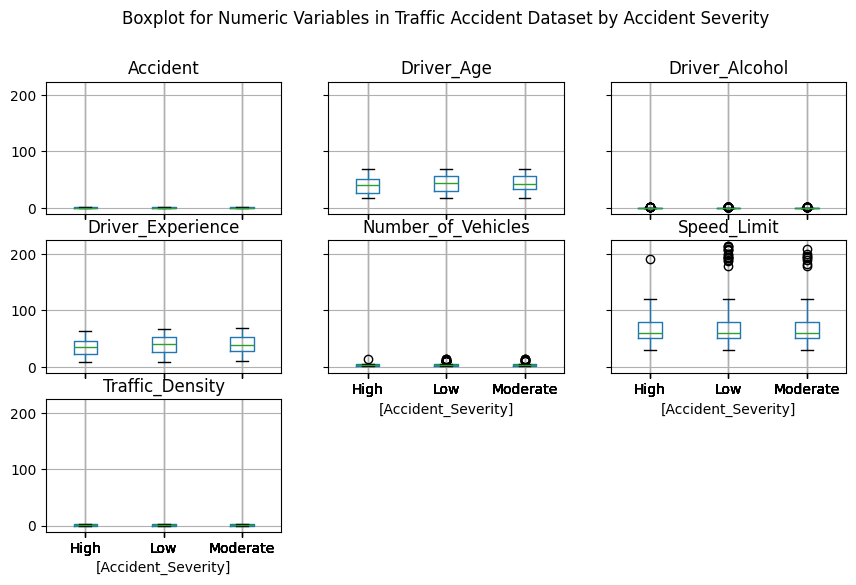

In [ ]:
df.boxplot(by='Accident_Severity', figsize=(10,6))
plt.suptitle('Boxplot for Numeric Variables in Traffic Accident Dataset by Accident Severity', y=1.02)
plt.show()

The boxplots show the distribution of numerical features in the dataset. They provide information about the median, minimum and maximum values, data spread, and the presence of outliers. By analyzing these details, we identified unusual values in some features, which helped us understand the data quality and determine the need for preprocessing steps, such as handling outliers, before further analysis.

**Outliers**

In [ ]:
numeric_columns = ['Traffic_Density', 'Speed_Limit', 'Number_of_Vehicles', 'Driver_Alcohol', 'Driver_Age', 'Driver_Experience', 'Accident']
threshold = 4
for column in numeric_columns:
    data = df[column].dropna()
    mean = np.mean(data)
    std_dev = np.std(data)
    outliers = [value for value in data if abs(value - mean) > threshold * std_dev]
    print(column, "Outliers:", outliers)

Traffic_Density Outliers: []
Speed_Limit Outliers: [200.0, 206.0, 208.0, 213.0, 213.0, 206.0, 212.0, 208.0]
Number_of_Vehicles Outliers: [12.0, 13.0, 12.0, 14.0, 14.0, 13.0, 14.0, 13.0, 14.0, 13.0]
Driver_Alcohol Outliers: []
Driver_Age Outliers: []
Driver_Experience Outliers: []
Accident Outliers: []


We used the Standard Deviation Method by calculating the difference by subtracting the mean from each value, then compared the result with the standard deviation threshold to detect outliers.

**Bar plots**

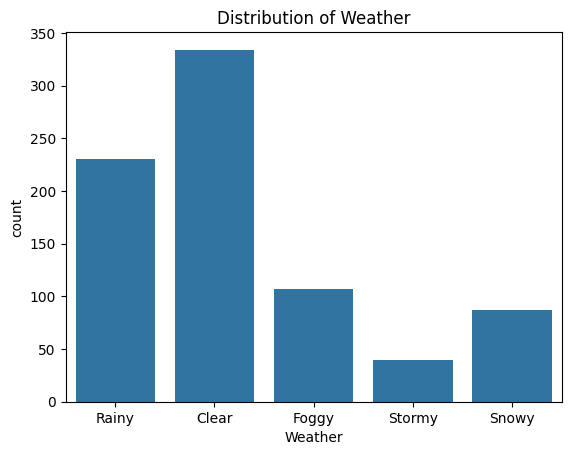

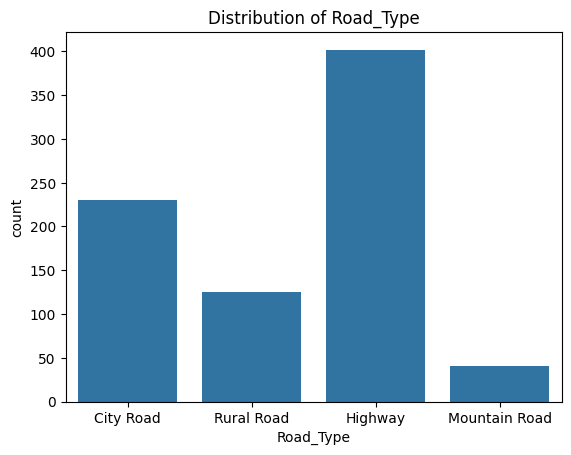

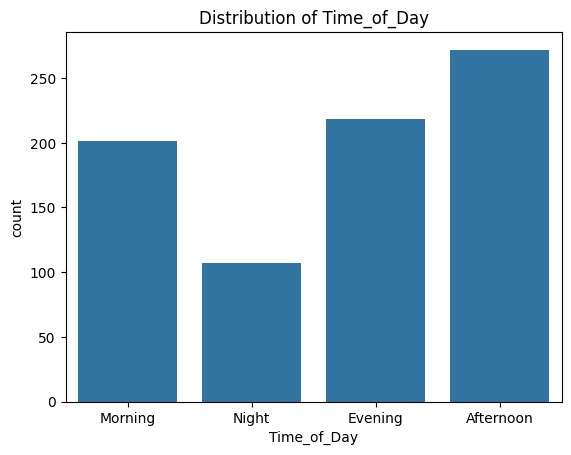

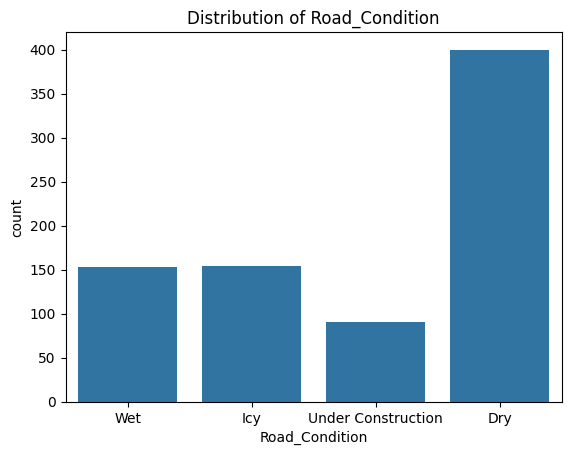

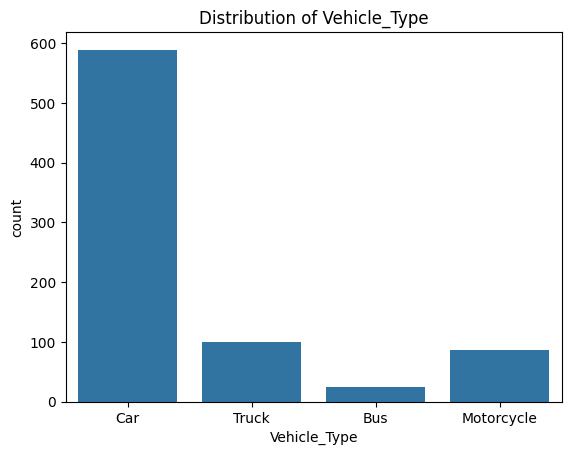

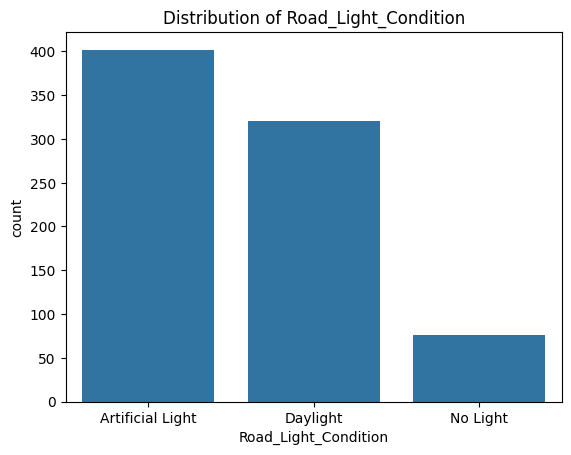

In [ ]:
cat_cols = ['Weather', 'Road_Type', 'Time_of_Day', 'Road_Condition', 'Vehicle_Type', 'Road_Light_Condition']
for col in cat_cols:
 sns.countplot(x=col, data=df)
 plt.title('Distribution of '+ col)
 plt.show()

These bar plots illustrate the frequency distributions of all nominal attributes in the dataset. The visualizations clearly reveal uneven distributions across several categories, highlighting the most dominant classes for each feature. Understanding these categorical distributions is a crucial part of our exploratory analysis, setting the foundation for the subsequent data cleaning and preprocessing steps.

**Class Label Distribution**

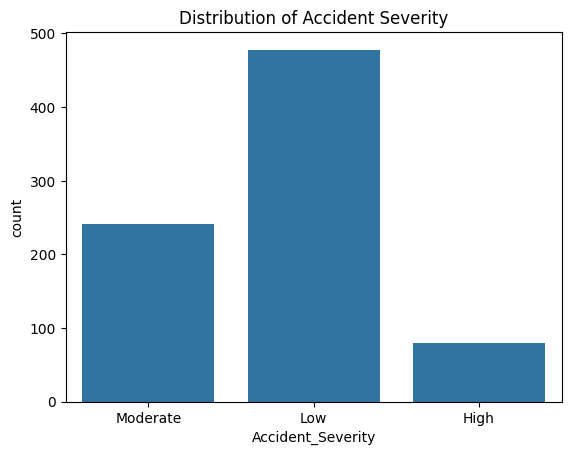

In [ ]:
sns.countplot(x='Accident_Severity', data=df)
plt.title('Distribution of Accident Severity')
plt.show()


This bar plot illustrates the distribution of the class label. It is clearly visible that the 'Low' category heavily dominates the dataset, while other classes are significantly less frequent. This uneven distribution highlights a class imbalance issue that might require attention during the modeling phase to prevent bias.

**Variables Relationship**

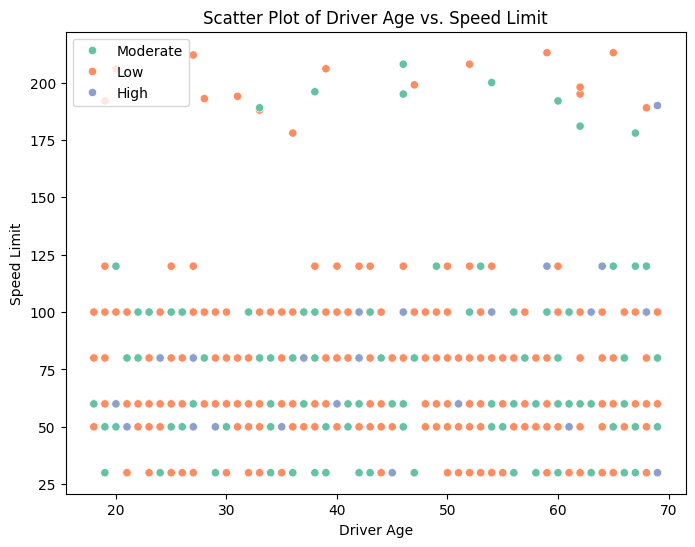

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Driver_Age', y='Speed_Limit', data=df, hue='Accident_Severity', palette='Set2')
plt.title('Scatter Plot of Driver Age vs. Speed Limit')
plt.xlabel('Driver Age')
plt.ylabel('Speed Limit')
plt.legend(loc='upper left')
plt.show()

This scatter plot explores the relationship between driver age and speed limits. The plot reveals the concentration of accidents in specific ranges, along with the presence of some scattered or extreme points. This observation strongly justifies the necessity of applying Noise Removal to clean the dataset from outliers.

**Variable Distributions**

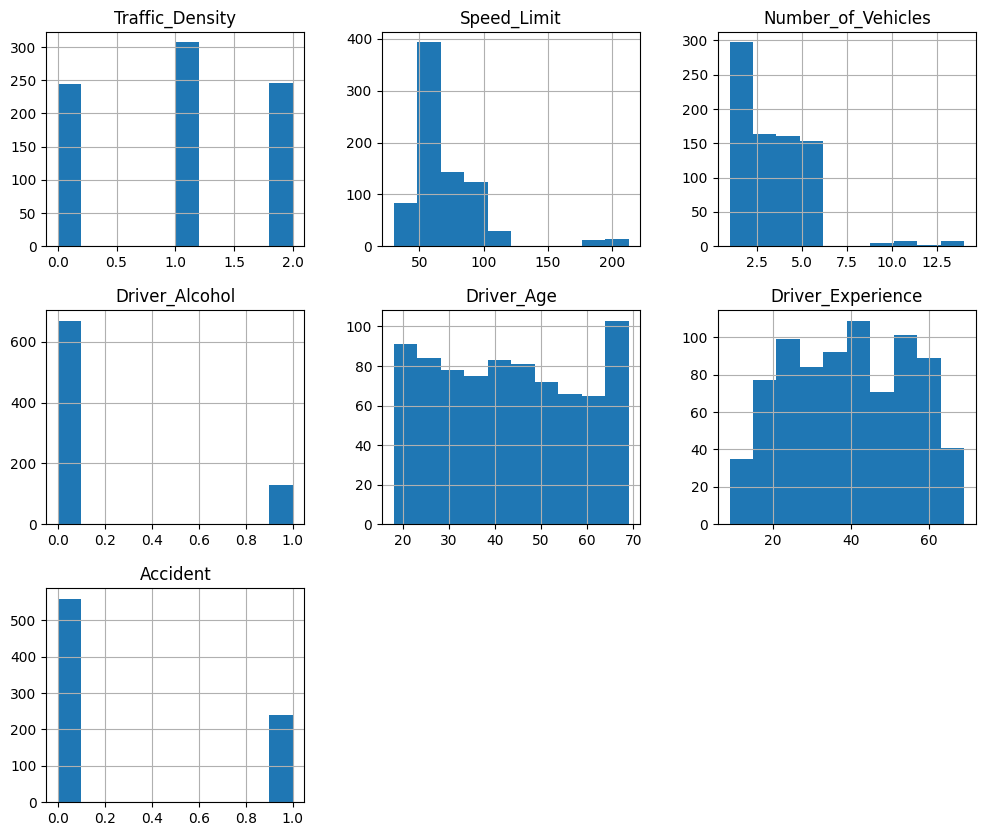

In [ ]:
df.hist(figsize=(12,10))
plt.show()

These histograms display the statistical distributions of the numeric variables. The clear differences in data scales across columns confirm that the raw data requires preprocessing. Consequently, we must apply Normalization to scale the data uniformly before feeding them into the predictive models.

**Missing Values Analysis**

In [ ]:

print("\nMissing Values:")
print (df.isnull().sum())


Missing Values:
Weather                 42
Road_Type               42
Time_of_Day             42
Traffic_Density         42
Speed_Limit             42
Number_of_Vehicles      42
Driver_Alcohol          42
Accident_Severity       42
Road_Condition          42
Vehicle_Type            42
Driver_Age              42
Driver_Experience       42
Road_Light_Condition    42
Accident                42
dtype: int64


In [ ]:

columns_mode = ['Driver_Alcohol', 'Accident']
for column in nun_numerical_columns:
  data = Preprocessed_dataset[column].dropna()
  column_mode = stats.mode(data).mode
  Preprocessed_dataset[column] = Preprocessed_dataset[column].fillna(column_mode)
print ("\nMissing Values:")
print (Preprocessed_dataset.isnull(). sum())


Missing Values:
Weather                 42
Road_Type               42
Time_of_Day             42
Traffic_Density          0
Speed_Limit             42
Number_of_Vehicles      42
Driver_Alcohol           0
Accident_Severity       42
Road_Condition          42
Vehicle_Type            42
Driver_Age              42
Driver_Experience       42
Road_Light_Condition    42
Accident                 0
dtype: int64


We handled the missing values in the binary and categorical attributes. Since these attributes can only take a fixed set of values (for example 0 or 1), we filled their missing values with the mode (most frequent value) instead of the mean. This keeps them as valid values and preserves their original meanin

In [ ]:
column_means = Preprocessed_dataset.mean(numeric_only=True)
Preprocessed_dataset= Preprocessed_dataset.fillna(column_means)
Preprocessed_dataset=Preprocessed_dataset.dropna()
print ("\nMissing Values:")
print (Preprocessed_dataset.isnull(). sum())


Missing Values:
Weather                 0
Road_Type               0
Time_of_Day             0
Traffic_Density         0
Speed_Limit             0
Number_of_Vehicles      0
Driver_Alcohol          0
Accident_Severity       0
Road_Condition          0
Vehicle_Type            0
Driver_Age              0
Driver_Experience       0
Road_Light_Condition    0
Accident                0
dtype: int64


We first checked for missing values in the dataset, then replaced the remaining missing numerical values with the column mean and removed rows with missing non-numerical values.

**Statistical Summaries**

In [ ]:
df.describe()

,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Driver_Age,Driver_Experience,Accident
count,798.000000,798.000000,798.000000,798.000000,798.000000,798.000000,798.000000
mean,1.001253,71.050125,3.286967,0.160401,43.259398,38.981203,0.299499
std,0.784894,32.052458,2.017267,0.367208,15.129856,15.273201,0.458326
min,0.000000,30.000000,1.000000,0.000000,18.000000,9.000000,0.000000
25%,0.000000,50.000000,2.000000,0.000000,30.000000,26.000000,0.000000
50%,1.000000,60.000000,3.000000,0.000000,43.000000,39.000000,0.000000
75%,2.000000,80.000000,4.000000,0.000000,56.000000,52.750000,1.000000
max,2.000000,213.000000,14.000000,1.000000,69.000000,69.000000,1.000000


The count of each numeric attribute is 798 out of 840 records, which means each attribute has 42 missing values. Some columns cannot be analyzed with mean and std because of their data type, Traffic_Density is ordinal (0, 1, 2 represent traffic levels), while Driver_Alcohol and Accident are binary. But we can analyze the rest because they are numeric, Driver_Age (15/43=0.35) and Driver_Experience (15/38=0.39) are the most consistent, meaning their values stay fairly close to the average. Speed_Limit (32/71=0.45) and Number_of_Vehicles (2.02/3.29=0.61) are more spread out, meaning their values are far from the average and change a lot, with Number_of_Vehicles being the most spread out.

# [4] Data Preprocessing

**Applying preprocessing techniques**





**Raw Dataset Snapshot**

In [ ]:
df.head()

,Weather,Road_Type,Time_of_Day,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Accident_Severity,Road_Condition,Vehicle_Type,Driver_Age,Driver_Experience,Road_Light_Condition,Accident
0,Rainy,City Road,Morning,1.0,100.0,5.0,0.0,NaN,Wet,Car,51.0,48.0,Artificial Light,0.0
1,Clear,Rural Road,Night,NaN,120.0,3.0,0.0,Moderate,Wet,Truck,49.0,43.0,Artificial Light,0.0
2,Rainy,Highway,Evening,1.0,60.0,4.0,0.0,Low,Icy,Car,54.0,52.0,Artificial Light,0.0
3,Clear,City Road,Afternoon,2.0,60.0,3.0,0.0,Low,Under Construction,Bus,34.0,31.0,Daylight,0.0
4,Rainy,Highway,Morning,1.0,195.0,11.0,0.0,Low,Dry,Car,62.0,55.0,Artificial Light,1.0


**Noise Removal**

In [ ]:
outlier_columns = ['Speed_Limit', 'Number_of_Vehicles']
threshold = 4
for column in outlier_columns:
    data = Preprocessed_dataset[column].dropna()
    mean = np.mean(data)
    std_dev = np.std(data)
    outlier_indexes = [index for index, value in data.items()
                       if abs(value - mean) > threshold * std_dev]
    Preprocessed_dataset = Preprocessed_dataset.drop(outlier_indexes)

Justification (Why): To systematically detect and remove all statistical outliers that deviate significantly from the normal distribution of the data, preventing machine learning algorithms from being biased by extreme anomalies.

How you applied it: By applying the Standard Deviation (Z-score) method. We iterated through the selected columns, calculated the mean and standard deviation, identified the indices of all values where the absolute difference from the mean exceeded the threshold of 4 standard deviations, and removed those specific rows using the drop() function.

On which attributes: Applied to the Speed_Limit and Number_of_Vehicles attributes.

Preprocessing Results & Improvement: The dataset is now clean from all extreme values lying beyond 4 standard deviations in the targeted columns. This creates a highly stable, robust, and normally distributed dataset, ensuring the algorithms build accurate assumptions during training.

**Normalization**

In [ ]:

columns_to_normalize = ['Speed_Limit', 'Number_of_Vehicles', 'Driver_Experience', 'Traffic_Density']
data_to_normalize = Preprocessed_dataset[columns_to_normalize]
minmax_scaler = MinMaxScaler()
normalized_data_minmax = minmax_scaler.fit_transform(data_to_normalize)
Preprocessed_dataset[columns_to_normalize] = normalized_data_minmax

Justification (Why): To scale the features to a standard range, ensuring that variables with large numeric values do not unfairly dominate the model's performance and that all features contribute equally.

 How you applied it: Used the ⁠MinMaxScaler⁠ from ⁠sklearn.preprocessing⁠ to apply Min-Max scaling, which transforms all values of the target attributes into a uniform range between 0 and 1.

On which attributes: Applied to the ⁠Speed_Limit⁠, ⁠Number_of_Vehicles⁠, ⁠Driver_Experience⁠, and ⁠Traffic_Density⁠ attributes.

 Preprocessing Results & Improvement: All values across these features are now confined within a standard unified range (between 0 and 1). This improves the dataset's efficiency by speeding up algorithm convergence and preventing bias caused by disparities in absolute number sizes across different variables.

**Discretization using equal-width binning**

In [ ]:
Preprocessed_dataset['Driver_Age'] = pd.cut(
    Preprocessed_dataset['Driver_Age'],
    bins=3,
    labels=['Young', 'Middle-aged', 'Older']
)


Justification (Why): To simplify the Driver_Age feature by grouping individual numerical age values into broader categories, making age-related patterns in traffic accidents easier to interpret and reducing the number of distinct values.

How you applied it: Used the pd.cut() function from Pandas to apply equal-width discretization, dividing the age range into three intervals of approximately equal width and replacing the original numerical values with the category labels Young, Middle-aged, and Older.

On which attributes: Applied to the Driver_Age attribute.

Preprocessing Results & Improvement: The numerical Driver_Age values were replaced with three categorical age groups: Young (18–34), Middle-aged (35–51), and Older (52–69). This provides a simpler and more interpretable representation of driver age and makes it easier to identify patterns between age groups and accident characteristics.

**Preprocessed Dataset Snapshot**

In [ ]:
Preprocessed_dataset.head()

,Weather,Road_Type,Time_of_Day,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Accident_Severity,Road_Condition,Vehicle_Type,Driver_Age,Driver_Experience,Road_Light_Condition,Accident
1,Clear,Rural Road,Night,0.5,1.000000,0.50,0.0,Moderate,Wet,Truck,Middle-aged,0.566667,Artificial Light,0.0
2,Rainy,Highway,Evening,0.5,0.333333,0.75,0.0,Low,Icy,Car,Older,0.716667,Artificial Light,0.0
3,Clear,City Road,Afternoon,1.0,0.333333,0.50,0.0,Low,Under Construction,Bus,Young,0.366667,Daylight,0.0
6,Foggy,Highway,Afternoon,0.0,0.333333,0.75,0.0,Low,Dry,Truck,Young,0.283333,Daylight,1.0
7,Rainy,City Road,Afternoon,0.0,0.333333,0.75,0.0,Low,Dry,Car,Young,0.216667,Artificial Light,1.0


In [ ]:
Preprocessed_dataset.to_csv('Preprocessed_dataset.csv', index=False)

# [5] Data Mining Technique

In this project, we will apply two data mining techniques to the preprocessed dataset: **classification** using Decision Trees, and **clustering** using K-means. Both techniques will be implemented in Python using the **scikit-learn** library.

## Classification: Decision Tree

**What:** A Decision Tree is a supervised learning technique that classifies records by learning a set of if-then rules from the training data. Each internal node tests an attribute, and each leaf node assigns a class label.

**Why:** We will use the Decision Tree because our class attribute "Accident_Severity" is categorical with three values (Low, Moderate, High). The resulting tree is also easy to visualize and interpret, which will help us understand which factors are related to accident severity.

**How:**
- **Encoding:** Since scikit-learn only accepts numerical data, the nominal attributes ("Weather", "Road_Type", "Time_of_Day", "Road_Condition", "Vehicle_Type", "Driver_Age", and "Road_Light_Condition") will be encoded using "LabelEncoder" from "sklearn.preprocessing".
- **Splitting:** The dataset will be split into training and testing sets using "train_test_split" from "sklearn.model_selection", with three partition sizes: 90/10, 80/20, and 70/30, and "random_state=1" to make the results reproducible.
- **Building the model:** We will use "DecisionTreeClassifier" from "sklearn.tree" with two attribute selection measures: the **Gini index** (the default) and **Information Gain** using criterion="entropy".
- **Evaluation:** Each model will be evaluated using "accuracy_score", "confusion_matrix", and "ConfusionMatrixDisplay" from "sklearn.metrics", and the final tree will be visualized using "plot_tree" from "sklearn.tree".

## Clustering: K-means

**What:** K-means is an unsupervised learning technique that partitions the records into K groups, where each record belongs to the cluster with the nearest centroid (mean).

**Why:** We will use K-means to discover groups of similar traffic accident records without using the class label, and then examine whether these groups are related to different levels of accident severity.

**How:**
- **Attribute selection:** K-means relies on Euclidean distance and means, so it will be applied to the numerical attributes only ("Traffic_Density", "Speed_Limit", "Number_of_Vehicles", "Driver_Alcohol", "Driver_Experience", and "Accident"). The class label "Accident_Severity" will be excluded.
- **Scaling:** The selected attributes will be scaled using "StandardScaler" from "sklearn.preprocessing".
- **Building the model:** We will use "KMeans" from "sklearn.cluster" with three different values of K (2, 3, and 4).
- **Choosing K and evaluation:** The number of clusters will be evaluated using the **Elbow method** (total within-cluster sum of squares, "inertia_"), the **Silhouette coefficient** ("silhouette_score" and "SilhouetteVisualizer" from "yellowbrick"), and the **Calinski-Harabasz index** ("calinski_harabasz_score").

# [6] Evaluation and Comparison

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/sadeembader/Mining_project/refs/heads/main/Dataset/Preprocessed_dataset.csv')
print(df.head())

  Weather   Road_Type Time_of_Day  Traffic_Density  Speed_Limit  \
0   Clear  Rural Road       Night         0.500627     1.000000   
1   Rainy     Highway     Evening         0.500000     0.333333   
2   Clear   City Road   Afternoon         1.000000     0.333333   
3   Foggy     Highway   Afternoon         0.000000     0.333333   
4   Rainy   City Road   Afternoon         0.000000     0.333333   

   Number_of_Vehicles  Driver_Alcohol Accident_Severity      Road_Condition  \
0                0.50             0.0          Moderate                 Wet   
1                0.75             0.0               Low                 Icy   
2                0.50             0.0               Low  Under Construction   
3                0.75             0.0               Low                 Dry   
4                0.75             0.0               Low                 Dry   

  Vehicle_Type   Driver_Age  Driver_Experience Road_Light_Condition  Accident  
0        Truck  Middle-aged           0.56

## **Classification**

## Importing Libraries for Classification

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
le = LabelEncoder()
df['Weather'] = le.fit_transform(df['Weather'])
df['Road_Type'] = le.fit_transform(df['Road_Type'])
df['Time_of_Day'] = le.fit_transform(df['Time_of_Day'])
df['Road_Condition'] = le.fit_transform(df['Road_Condition'])
df['Vehicle_Type'] = le.fit_transform(df['Vehicle_Type'])
df['Driver_Age'] = le.fit_transform(df['Driver_Age'])
df['Road_Light_Condition'] = le.fit_transform(df['Road_Light_Condition'])
print(df.head())


   Weather  Road_Type  Time_of_Day  Traffic_Density  Speed_Limit  \
0        0          3            3         0.500627     1.000000   
1        2          1            1         0.500000     0.333333   
2        0          0            0         1.000000     0.333333   
3        1          1            0         0.000000     0.333333   
4        2          0            0         0.000000     0.333333   

   Number_of_Vehicles  Driver_Alcohol Accident_Severity  Road_Condition  \
0                0.50             0.0          Moderate               3   
1                0.75             0.0               Low               1   
2                0.50             0.0               Low               2   
3                0.75             0.0               Low               0   
4                0.75             0.0               Low               0   

   Vehicle_Type  Driver_Age  Driver_Experience  Road_Light_Condition  Accident  
0             3           0           0.566667             

In [ ]:
#split dataset in features and target variable
fn = df.keys().tolist()
fn.remove('Accident_Severity')
X = df[fn]
y = df['Accident_Severity']

In [ ]:
cn = ['High', 'Moderate', 'Low']

### Decision Tree Classification Using Gini

In [ ]:
# Split dataset into 90% training set and 10% test set
X_train1, X_test1, y_train1, y_test1 = train_test_split(X, y, test_size=0.1, random_state=1)

In [ ]:
# Gini Decision Tree – 90% Training / 10% Testing
clf_Gini1 = DecisionTreeClassifier(random_state=1)
clf_Gini1 = clf_Gini1.fit(X_train1,y_train1)
y_pred1 = clf_Gini1.predict(X_test1)

print("Accuracy (Gini 90/10):",metrics.accuracy_score(y_test1, y_pred1))

Accuracy (Gini 90/10): 0.4827586206896552


[[ 1  3  3]
 [ 6  7  5]
 [ 3 10 20]]


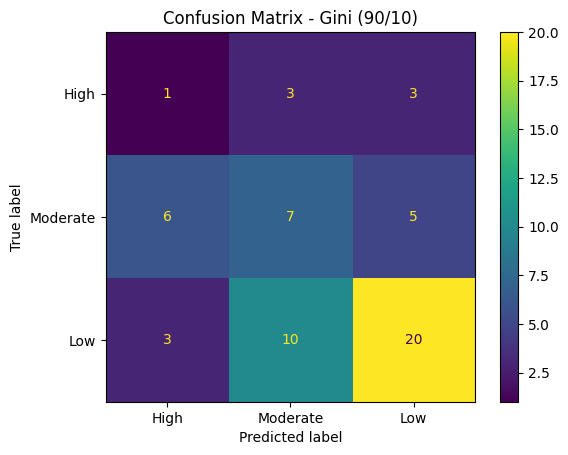

In [ ]:
#Confusion Matrix - Gini (90/10)
cm_Gini1= confusion_matrix(y_test1, y_pred1,labels=cn)
print(cm_Gini1)

disp_Gini1 = ConfusionMatrixDisplay.from_estimator(clf_Gini1, X_test1, y_test1, labels=cn, display_labels=cn)
plt.title('Confusion Matrix - Gini (90/10)')
plt.show()

In [ ]:
# Split dataset into 80% training set and 20% test set
X_train2, X_test2, y_train2, y_test2 = train_test_split(X, y, test_size=0.2, random_state=1)

In [ ]:
# Gini Decision Tree – 80% Training / 20% Testing
clf_Gini2= DecisionTreeClassifier(random_state=1)
clf_Gini2 = clf_Gini2.fit(X_train2,y_train2)
y_pred2 = clf_Gini2.predict(X_test2)

print("Accuracy (Gini 80/20):",metrics.accuracy_score(y_test2, y_pred2))

Accuracy (Gini 80/20): 0.4260869565217391


[[ 2  2  9]
 [ 3  9 23]
 [ 9 20 38]]


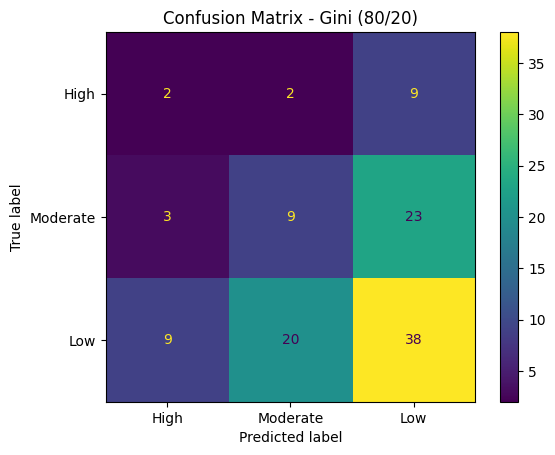

In [ ]:
#Confusion Matrix - Gini (80/20)
cm_Gini2= confusion_matrix(y_test2, y_pred2,labels=cn)
print(cm_Gini2)

disp_Gini2 = ConfusionMatrixDisplay.from_estimator(clf_Gini2, X_test2, y_test2, labels=cn, display_labels=cn)
plt.title('Confusion Matrix - Gini (80/20)')
plt.show()

In [ ]:
# Split dataset into 70% training set and 30% test set
X_train3, X_test3, y_train3, y_test3 = train_test_split(X, y, test_size=0.3, random_state=1)

In [ ]:
# Gini Decision Tree – 70% Training / 30% Testing
clf_Gini3 = DecisionTreeClassifier(random_state=1)
clf_Gini3 = clf_Gini3.fit(X_train3,y_train3)
y_pred3 = clf_Gini3.predict(X_test3)

print("Accuracy (Gini 70/30):",metrics.accuracy_score(y_test3, y_pred3))

Accuracy (Gini 70/30): 0.45930232558139533


[[ 3  6  8]
 [ 5 13 33]
 [13 28 63]]


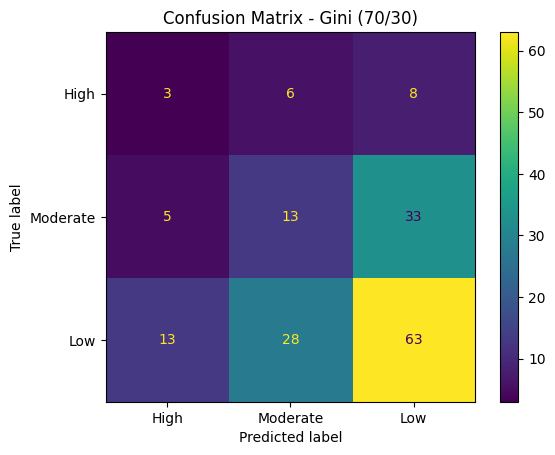

In [ ]:
# Confusion Matrix - Gini (70/30)
cm_Gini3= confusion_matrix(y_test3, y_pred3,labels=cn)
print(cm_Gini3)

disp_Gini3 = ConfusionMatrixDisplay.from_estimator(clf_Gini3, X_test3, y_test3, labels=cn, display_labels=cn)
plt.title('Confusion Matrix - Gini (70/30)')
plt.show()

In [ ]:

df_gini = pd.DataFrame(np.array([[metrics.accuracy_score(y_test1, y_pred1), metrics.accuracy_score(y_test2, y_pred2), metrics.accuracy_score(y_test3, y_pred3)]]),
                       columns=['90% training set 10% testing set:' , '80% training set 20% testing set:', '70% training set 30% testing set:'],
                       index=['Accuracy (Gini)'])

df_gini


,90% training set 10% testing set:,80% training set 20% testing set:,70% training set 30% testing set:
Accuracy (Gini),0.482759,0.426087,0.459302


### Decision Tree Classification Using Entropy (Information Gain)

In [ ]:

# Entropy Decision Tree - 90% Training / 10% Testing

clf_entropy1 = DecisionTreeClassifier(
    criterion="entropy",
    random_state=1
)

clf_entropy1 = clf_entropy1.fit(X_train1, y_train1)

y_pred_entropy1 = clf_entropy1.predict(X_test1)

print("Accuracy (Entropy 90/10):",
      metrics.accuracy_score(y_test1, y_pred_entropy1))


Accuracy (Entropy 90/10): 0.41379310344827586


In [ ]:
cn = ['High', 'Moderate', 'Low']

[[ 1  2  4]
 [ 2  7  9]
 [ 5 12 16]]


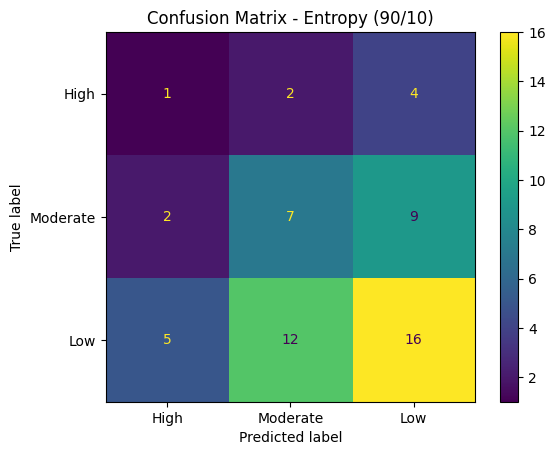

In [ ]:
# Confusion Matrix - Entropy (90/10)
cm_entropy1 = confusion_matrix(y_test1, y_pred_entropy1, labels=cn)
print(cm_entropy1)

disp_entropy1 = ConfusionMatrixDisplay.from_estimator(clf_entropy1, X_test1, y_test1, labels=cn, display_labels=cn)
plt.title("Confusion Matrix - Entropy (90/10)")
plt.show()

In [ ]:

# Entropy Decision Tree - 80% Training / 20% Testing

clf_entropy2 = DecisionTreeClassifier(
    criterion="entropy",
    random_state=1
)

clf_entropy2 = clf_entropy2.fit(X_train2, y_train2)

y_pred_entropy2 = clf_entropy2.predict(X_test2)

print("Accuracy (Entropy 80/20):",
      metrics.accuracy_score(y_test2, y_pred_entropy2))


Accuracy (Entropy 80/20): 0.4434782608695652


[[ 2  5  6]
 [ 6  9 20]
 [11 16 40]]


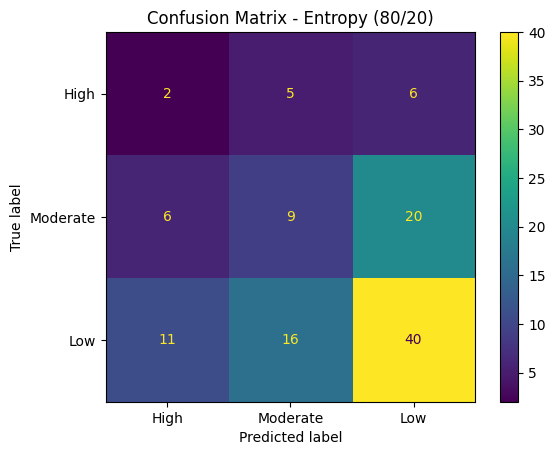

In [ ]:
# Confusion Matrix - Entropy (80/20)
cm_entropy2 = confusion_matrix(y_test2, y_pred_entropy2, labels=cn)
print(cm_entropy2)

disp_entropy2 = ConfusionMatrixDisplay.from_estimator(clf_entropy2, X_test2, y_test2, labels=cn, display_labels=cn)
plt.title("Confusion Matrix - Entropy (80/20)")
plt.show()

In [ ]:

# Entropy Decision Tree - 70% Training / 30% Testing

clf_entropy3 = DecisionTreeClassifier(
    criterion="entropy",
    random_state=1
)

clf_entropy3 = clf_entropy3.fit(X_train3, y_train3)

y_pred_entropy3 = clf_entropy3.predict(X_test3)

print("Accuracy (Entropy 70/30):",
      metrics.accuracy_score(y_test3, y_pred_entropy3))


Accuracy (Entropy 70/30): 0.5


[[ 4  3 10]
 [ 5 14 32]
 [13 23 68]]


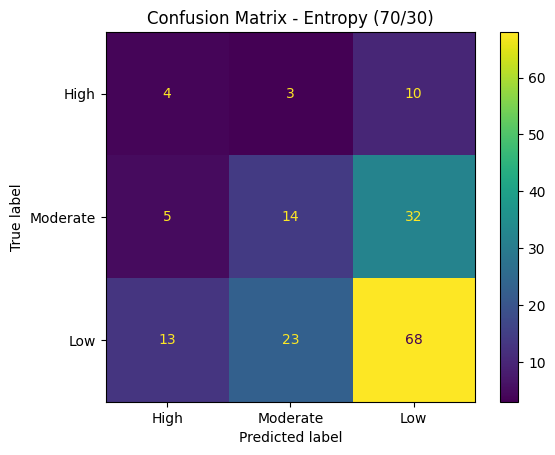

In [ ]:
# Confusion Matrix - Entropy (70/30)
cm_entropy3 = confusion_matrix(y_test3, y_pred_entropy3, labels=cn)
print(cm_entropy3)

disp_entropy3 = ConfusionMatrixDisplay.from_estimator(clf_entropy3, X_test3, y_test3, labels=cn, display_labels=cn)
plt.title("Confusion Matrix - Entropy (70/30)")
plt.show()

In [ ]:

# Entropy Accuracy Comparison Table

df_entropy = pd.DataFrame(
    np.array([[
        metrics.accuracy_score(y_test1, y_pred_entropy1),
        metrics.accuracy_score(y_test2, y_pred_entropy2),
        metrics.accuracy_score(y_test3, y_pred_entropy3)
    ]]),
    columns=[
        '90% training set 10% testing set:',
        '80% training set 20% testing set:',
        '70% training set 30% testing set:'
    ],
    index=['Accuracy (Entropy)']
)

df_entropy


,90% training set 10% testing set:,80% training set 20% testing set:,70% training set 30% testing set:
Accuracy (Entropy),0.413793,0.443478,0.5


### Comparison Between Gini Index and Entropy

In [ ]:

# Gini vs Entropy Accuracy Comparison

df_comparison = pd.DataFrame(
    [
        [
            metrics.accuracy_score(y_test1, y_pred1),
            metrics.accuracy_score(y_test2, y_pred2),
            metrics.accuracy_score(y_test3, y_pred3)
        ],
        [
            metrics.accuracy_score(y_test1, y_pred_entropy1),
            metrics.accuracy_score(y_test2, y_pred_entropy2),
            metrics.accuracy_score(y_test3, y_pred_entropy3)
        ]
    ],
    columns=['90/10', '80/20', '70/30'],
    index=['Accuracy (Gini)', 'Accuracy (Entropy)']
)

df_comparison



,90/10,80/20,70/30
Accuracy (Gini),0.482759,0.426087,0.459302
Accuracy (Entropy),0.413793,0.443478,0.500000


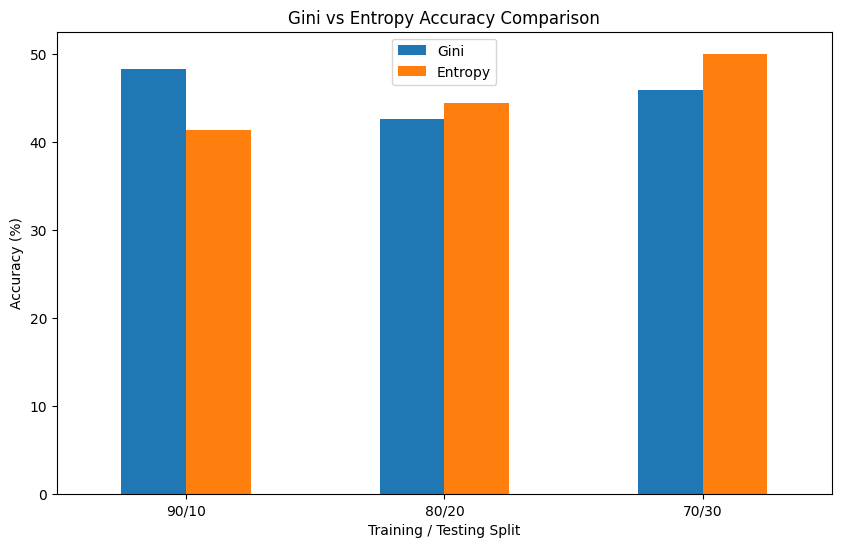

In [ ]:


# Gini vs Entropy Accuracy Comparison Chart

(df_comparison.T * 100).plot.bar(
    figsize=(10, 6)
)

plt.title('Gini vs Entropy Accuracy Comparison')
plt.xlabel('Training / Testing Split')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation=0)
plt.legend(['Gini', 'Entropy'])
plt.show()



### Classification Results and Comparison

The Decision Tree classifier was evaluated using two attribute selection measures, Gini Index and Entropy (Information Gain), across three training/testing partitions: 90/10, 80/20, and 70/30.

For the 90/10 partition, Gini achieved higher accuracy (48.28%) compared to Entropy (41.38%). However, Entropy outperformed Gini in the remaining two partitions. For the 80/20 split, Entropy achieved 44.35% accuracy compared to 42.61% for Gini. Similarly, for the 70/30 split, Entropy achieved 50.00% accuracy, while Gini achieved 45.93%.

Overall, Entropy with the 70/30 partition achieved the highest observed accuracy of 50.00%, making it the best-performing configuration among the six experiments. Entropy also performed better in two out of the three partitions.



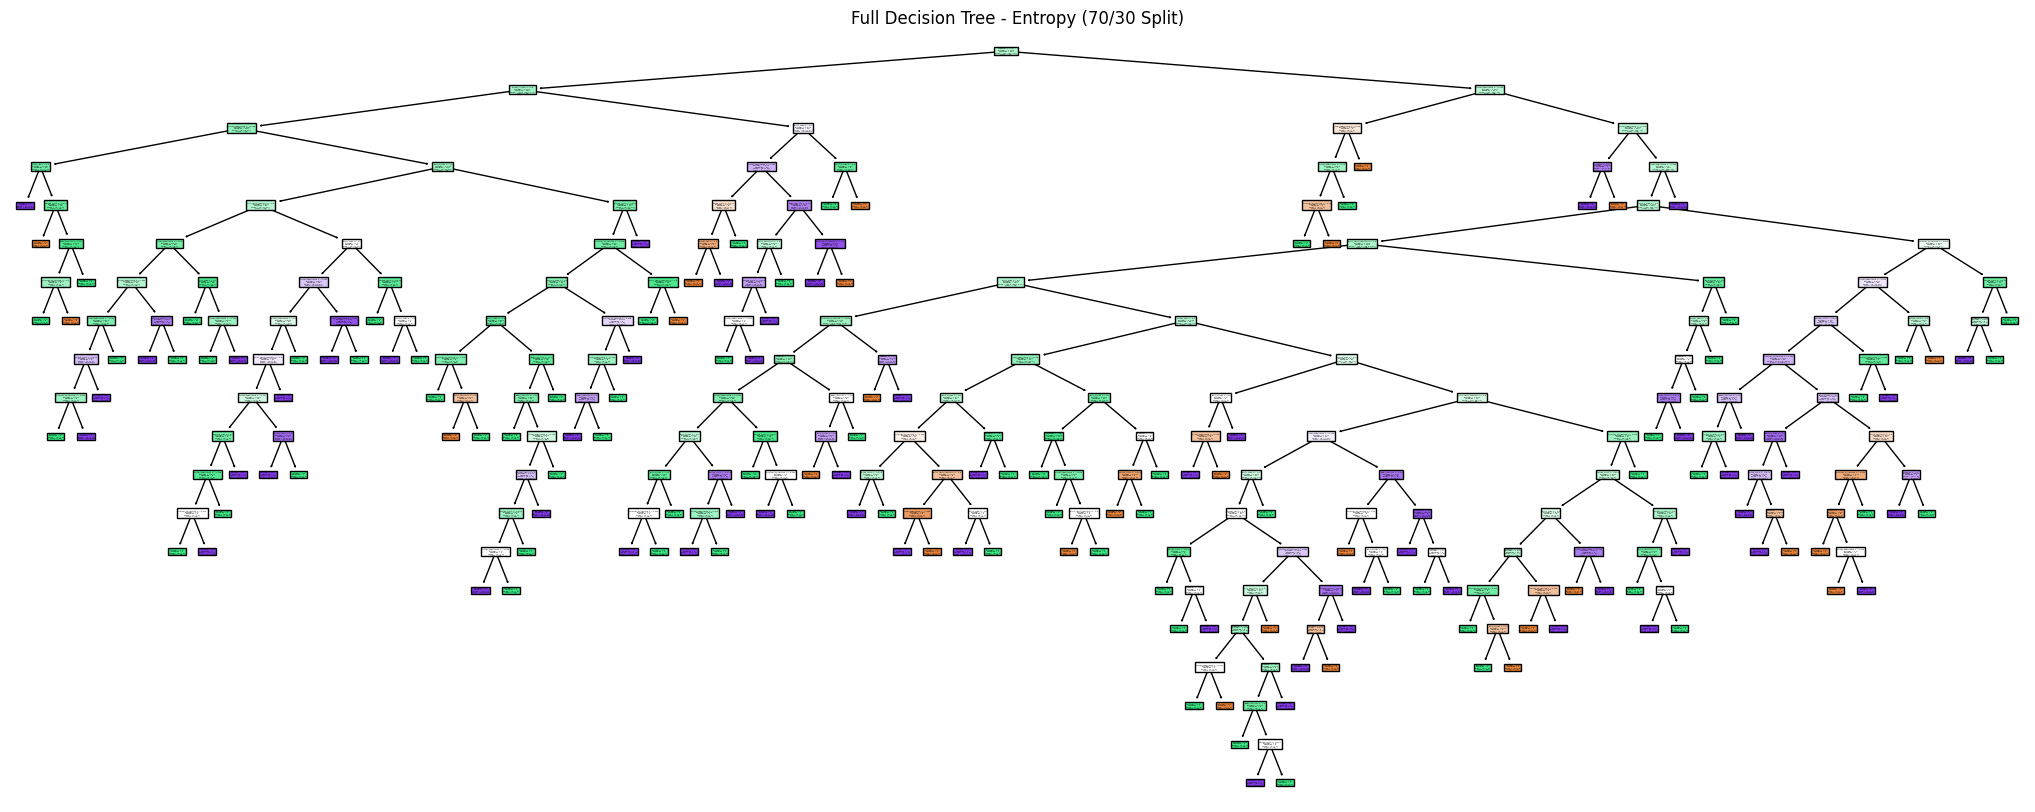

In [ ]:
# Full Decision Tree (Entropy 70/30)
# Best observed model: Entropy (70/30)

fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10))
tree.plot_tree(clf_entropy3,
               feature_names=fn,
               class_names=clf_entropy3.classes_,
               filled=True)
plt.title("Full Decision Tree - Entropy (70/30 Split)")
plt.show()

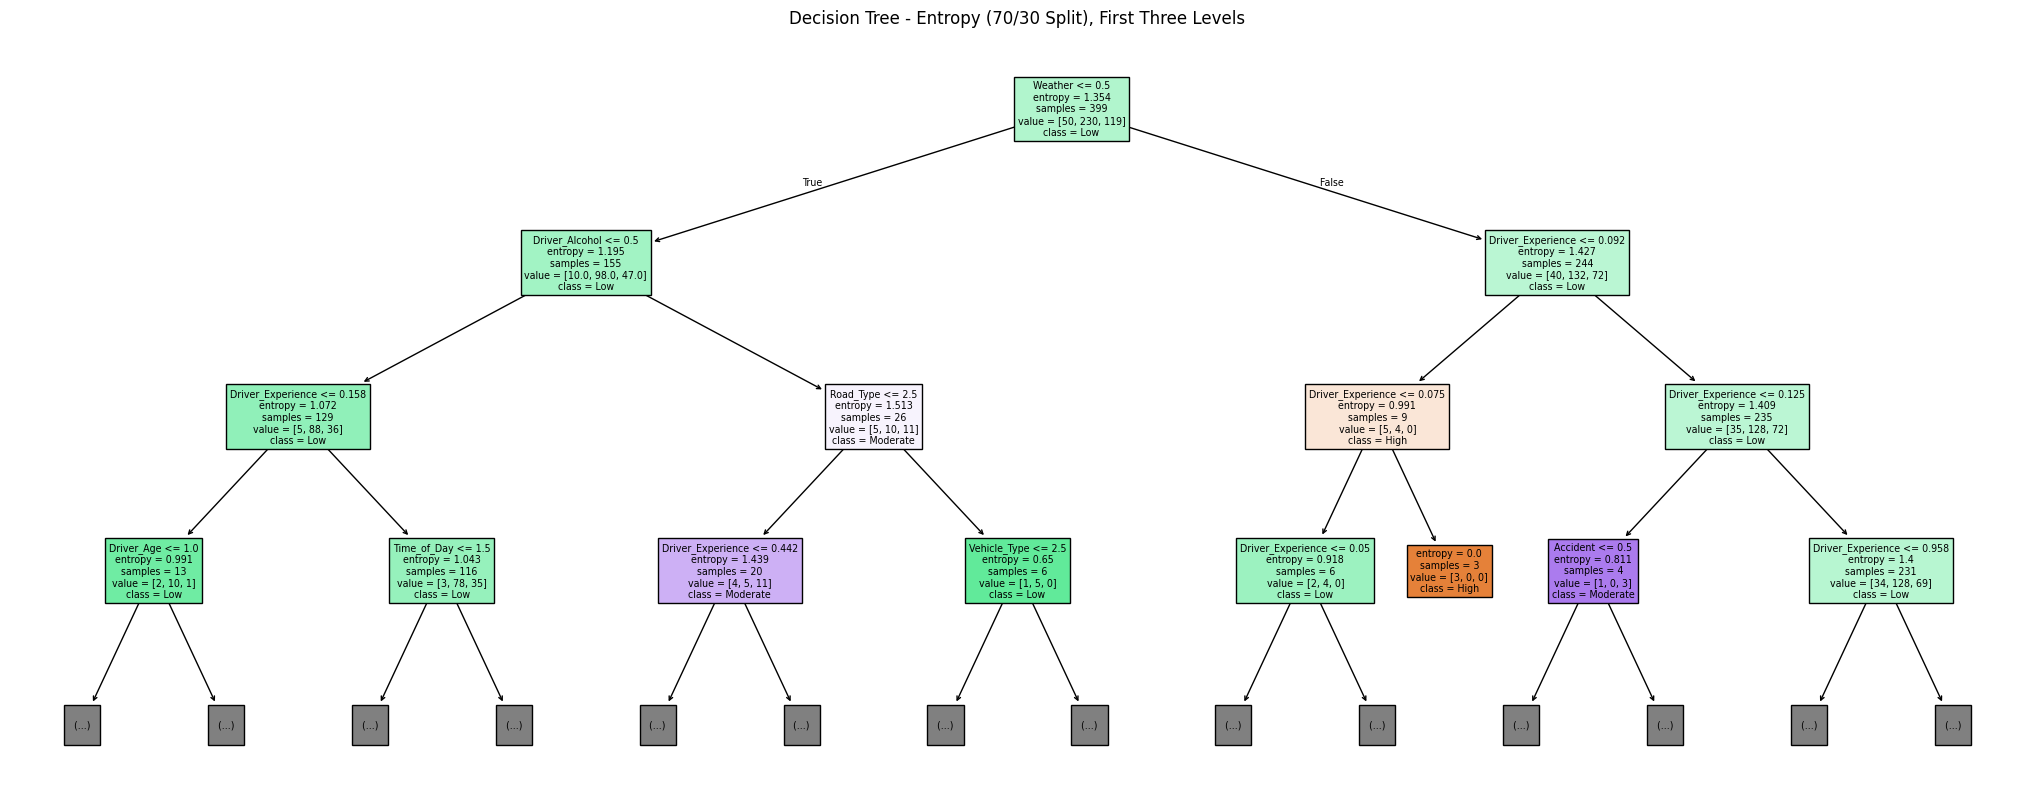

In [ ]:
# Decision Tree - First Three Levels (Entropy 70/30)
# Best observed model: Entropy (70/30)
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10))
tree.plot_tree(clf_entropy3,
               feature_names=fn,
               class_names=clf_entropy3.classes_,
               filled=True,
               max_depth=3)
plt.title("Decision Tree - Entropy (70/30 Split), First Three Levels")
plt.show()

### Decision Tree Interpretation

The final Decision Tree visualization represents the Entropy classifier trained using the 70/30 partition, which achieved the highest observed classification accuracy of 50.00%.

 The first plot shows the full tree, which is very large and difficult to read. Therefore, the second plot displays the first three levels of the tree (max_depth=3), which contain the most important splits.

The root node uses **Weather** as the initial splitting attribute, indicating that the model selected this feature to separate the training instances based on Information Gain. Subsequent decisions involve **Driver_Alcohol**, **Driver_Experience**, **Road_Type**, **Driver_Age**, and other accident-related attributes.

The root node contains 399 training instances, with Low being the most frequent accident severity class (230 instances). The tree demonstrates how different combinations of attributes are used to classify accidents into High, Moderate, and Low severity levels.

However, the overall accuracy of 50.00% indicates that the model's predictive performance is limited. Therefore, although the Decision Tree provides interpretable classification rules, additional improvements may be necessary to achieve more reliable accident severity predictions.

## **Clustering**

### Importing Libraries for Clustering

In [ ]:
!pip install yellowbrick
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, silhouette_score
from sklearn.pipeline import make_pipeline
from yellowbrick.cluster import SilhouetteVisualizer

In [ ]:
df_cluster_raw = pd.read_csv('https://raw.githubusercontent.com/sadeembader/Mining_project/refs/heads/main/Dataset/Preprocessed_dataset.csv')

# Extract the numerical features (excluding nominal columns and target variable Accident_Severity)
numerical_features = ['Traffic_Density', 'Speed_Limit', 'Number_of_Vehicles', 'Driver_Alcohol', 'Driver_Experience', 'Accident']
features = df_cluster_raw[numerical_features]

# Use StandardScaler to scale the features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# Create a new DataFrame with the scaled features
features_scaled = pd.DataFrame(scaled_features, columns=features.columns)

# Display the scaled DataFrame
print("\nScaled DataFrame:")
print(features_scaled.head())


Scaled DataFrame:
   Traffic_Density  Speed_Limit  Number_of_Vehicles  Driver_Alcohol  \
0         0.001566     2.349361           -0.035156       -0.418207   
1        -0.000078    -0.329984            0.691919       -0.418207   
2         1.311364    -0.329984           -0.035156       -0.418207   
3        -1.311519    -0.329984            0.691919       -0.418207   
4        -1.311519    -0.329984            0.691919       -0.418207   

   Driver_Experience  Accident  
0           0.265917 -0.634782  
1           0.875019 -0.634782  
2          -0.546219 -0.634782  
3          -0.884608  1.575344  
4          -1.155320  1.575344  


### Justification for Selecting Only Numerical Attributes in K-Means

For K-Means clustering, we removed the class attribute (`Accident_Severity`) because clustering is an unsupervised technique, and we selected only the numerical attributes (`Traffic_Density`, `Speed_Limit`, `Number_of_Vehicles`, `Driver_Alcohol`, `Driver_Experience`, and `Accident`) while excluding the nominal attributes.

K-Means groups data points by calculating the **Euclidean distance** between points and updates cluster centers using the **mean** (average). Calculating distances and averages only makes sense with numerical data, because encoded nominal values represent categories rather than real quantities. We also applied `StandardScaler` so that all numerical features are on the same scale before clustering.

### 1. K-Means Clustering with K = 2

We selected K = 2 as the smallest meaningful number of clusters. It matches the binary nature of the Accident attribute (accident / no accident) and provides a baseline for comparison with larger values of K.

In [ ]:
# Set a seed for random number generation
np.random.seed(42)

# Run k-means clustering with 2 clusters
kmeans_2 = KMeans(n_clusters=2, n_init=10, random_state=42)
kmeans_result_2 = kmeans_2.fit(features_scaled)

# Print the clustering result
print("Cluster Centers:")
print(kmeans_result_2.cluster_centers_)
print("\nCluster Labels:")
print(kmeans_result_2.labels_)
print("\nTotal within-cluster sum of squares (WSS):", kmeans_result_2.inertia_)

Cluster Centers:
[[ 0.00321315  0.01476019 -0.03995516 -0.01095232 -0.02364451 -0.63478217]
 [-0.0079741  -0.03663046  0.09915702  0.02718046  0.05867876  1.57534356]]

Cluster Labels:
[0 0 0 1 1 0 0 1 0 0 1 0 0 0 1 0 0 1 0 0 0 1 1 0 0 0 0 0 1 0 0 0 1 0 1 0 0
 1 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 1 0 0 1 0 0 0 1 0 0 0 0 1 1 0 0 0 0 1 1 0
 0 1 0 0 0 0 0 1 0 0 0 1 1 1 0 1 0 1 0 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 0 0
 1 0 0 0 0 0 1 0 0 1 0 0 0 1 0 0 1 1 1 0 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0
 0 1 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 1 1 0 0
 0 0 0 0 0 1 1 1 1 0 1 1 0 0 1 0 0 1 1 1 0 0 0 0 0 1 0 1 0 0 1 0 0 0 1 0 0
 0 0 0 0 0 0 0 0 1 1 1 0 0 1 0 0 1 1 0 1 1 0 1 0 0 0 0 0 0 1 0 0 0 1 0 1 0
 1 0 0 1 1 1 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 1 1 0 1 0 0 1 0 1 1 0 0 0
 1 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 0 1
 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 1 1 1
 0 1 1 1 0 1 1 0 0 1 1 0 1 1 0 0 0 0 1 0 0 1 0 1 1 0 0 0 0 0 0 1 

The average silhouette score is: 0.20732881601497105


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


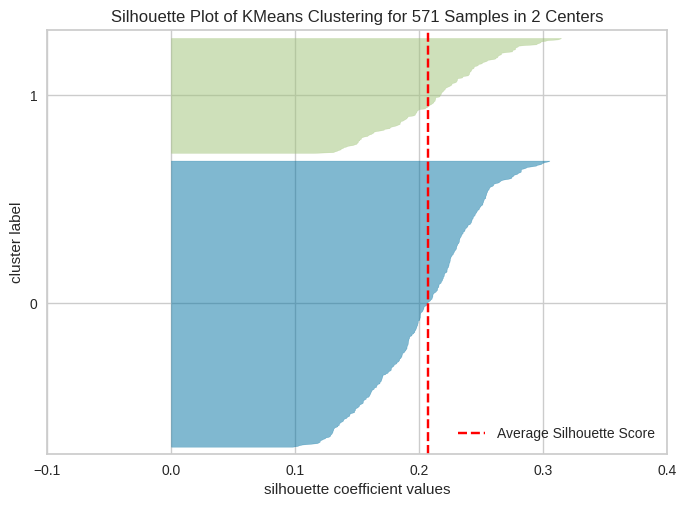

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 571 Samples in 2 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [ ]:
# Silhouette plot and average silhouette score
visualizer_2 = SilhouetteVisualizer(kmeans_2, colors="yellowbrick")
visualizer_2.fit(features_scaled)
print("The average silhouette score is:", visualizer_2.silhouette_score_)
visualizer_2.show()

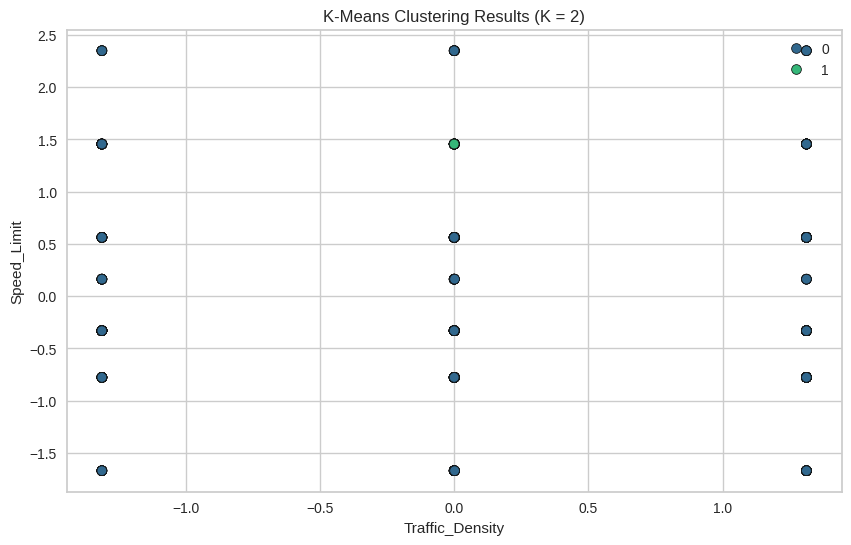

In [ ]:
# Add cluster labels to a copy of the scaled DataFrame for visualization
plot_k2 = features_scaled.copy()
plot_k2['Cluster'] = kmeans_result_2.labels_

# Visualize clustering using a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x=plot_k2.columns[0], y=plot_k2.columns[1], hue='Cluster', data=plot_k2, palette='viridis', edgecolor='k')
plt.title('K-Means Clustering Results (K = 2)')
plt.xlabel(plot_k2.columns[0])
plt.ylabel(plot_k2.columns[1])
plt.legend()
plt.show()

**Interpretation of Results (K = 2):**
* **Average Silhouette Width:** `0.2073`, which indicates relatively weak separation between the two clusters. In the Silhouette plot, Cluster 0 is much thicker than Cluster 1, showing that most records are grouped into one large cluster while many points fall below the red average score line.
* **Total Within-Cluster Sum of Squares (WSS):** `2851.4522`, which is high and shows that the data points are still far from their cluster centers.
* **Cluster Visualization:** The scatter plot of Traffic_Density versus Speed_Limit shows the two clusters overlapping, because these two attributes do not separate the clusters. The cluster centers show that the two clusters differ only in the Accident attribute (standardized values ≈ −0.63 versus ≈ +1.58).

### 2. K-Means Clustering with K = 3

We selected K = 3 because the class attribute Accident_Severity has three levels (Low, Moderate, High), so we can examine whether three clusters correspond to the severity levels.

In [ ]:
# Set a seed for random number generation
np.random.seed(42)

# Run k-means clustering with 3 clusters
kmeans_3 = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_result_3 = kmeans_3.fit(features_scaled)

# Print the clustering result
print("Cluster Centers:")
print(kmeans_result_3.cluster_centers_)
print("\nCluster Labels:")
print(kmeans_result_3.labels_)
print("\nTotal within-cluster sum of squares (WSS):", kmeans_result_3.inertia_)

Cluster Centers:
[[-3.79952419e-02  2.44311768e-02  1.53050351e-01 -4.18207029e-01
   2.01427447e-02  1.57534356e+00]
 [ 1.88356803e-02  2.22725120e-03 -5.36135996e-02 -4.18207029e-01
  -1.80815031e-02 -6.34782170e-01]
 [-1.54290982e-02 -4.87833626e-02 -2.89813616e-02  2.39116019e+00
   4.13254624e-02  4.12562874e-02]]

Cluster Labels:
[1 1 1 0 0 1 1 0 1 1 0 1 1 1 2 1 1 0 1 1 1 0 0 1 1 2 2 1 2 1 2 2 0 1 0 1 2
 2 1 1 1 2 1 1 1 1 0 0 0 1 1 1 1 0 1 1 0 1 2 1 2 1 1 1 1 2 2 1 2 1 1 0 2 1
 1 0 1 1 1 1 1 0 1 1 1 2 0 0 1 0 1 0 1 1 1 0 1 0 1 1 2 2 1 2 0 1 2 1 1 1 1
 0 1 1 2 1 1 0 1 1 0 1 1 2 0 1 1 0 0 2 1 1 0 1 0 1 1 1 1 1 1 2 1 2 1 1 1 1
 1 0 1 1 1 1 1 1 1 0 1 0 2 1 1 1 1 1 0 2 1 1 2 1 1 0 1 0 1 2 1 1 1 0 0 1 1
 1 1 2 1 1 0 2 0 0 1 0 0 1 1 0 1 1 0 0 0 1 2 1 1 1 0 2 2 1 2 0 1 1 2 0 2 2
 1 1 1 1 1 1 1 1 2 0 2 1 1 0 1 2 0 0 1 0 0 1 0 1 2 1 1 1 1 0 1 1 1 0 1 0 2
 0 1 1 0 0 0 1 0 1 1 2 1 1 0 1 1 1 1 1 1 1 1 1 0 0 0 1 0 1 1 0 1 0 0 1 1 1
 2 0 1 0 1 1 1 0 1 1 1 2 1 1 1 1 1 1 1 0 1 2 1 1 1 1 2 1 1 1 0

The average silhouette score is: 0.23682640782618145


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


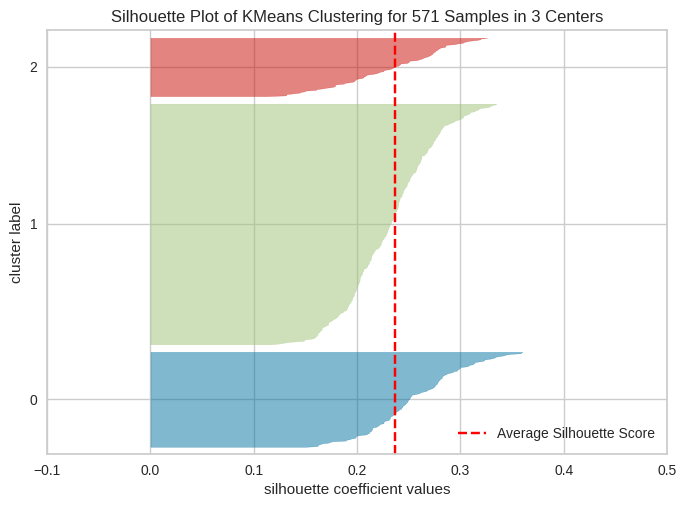

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 571 Samples in 3 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [ ]:
# Silhouette plot and average silhouette score
visualizer_3 = SilhouetteVisualizer(kmeans_3, colors="yellowbrick")
visualizer_3.fit(features_scaled)
print("The average silhouette score is:", visualizer_3.silhouette_score_)
visualizer_3.show()

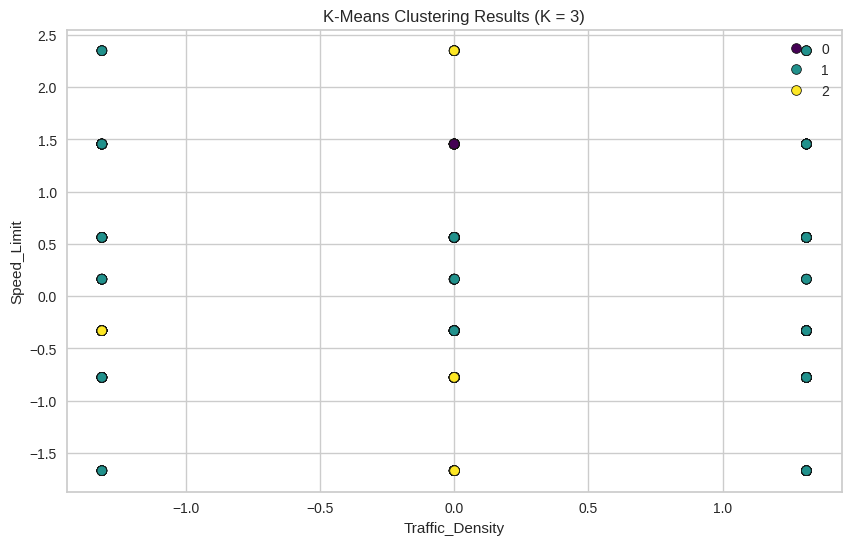

In [ ]:
# Add cluster labels to a copy of the scaled DataFrame for visualization
plot_k3 = features_scaled.copy()
plot_k3['Cluster'] = kmeans_result_3.labels_

# Visualize clustering using a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x=plot_k3.columns[0], y=plot_k3.columns[1], hue='Cluster', data=plot_k3, palette='viridis', edgecolor='k')
plt.title('K-Means Clustering Results (K = 3)')
plt.xlabel(plot_k3.columns[0])
plt.ylabel(plot_k3.columns[1])
plt.legend()
plt.show()

**Interpretation of Results (K = 3):**
* **Average Silhouette Width:** Improved to `0.2368` (the highest among the tested values), which indicates better cohesion and separation than $K = 2$. The Silhouette plot shows no negative silhouette values for the three clusters, although a large part of each cluster is below the average line, which indicates moderate (not strong) separation.
* **Total Within-Cluster Sum of Squares (WSS):** Dropped noticeably to `2366.9052` (a decrease of about `484.55` compared to $K = 2$), showing that the clusters are more compact.
* **Cluster Visualization:** The scatter plot of Traffic_Density versus Speed_Limit shows the three clusters overlapping, because these attributes have almost identical centers in all clusters. According to the cluster centers, the clusters are separated by Accident and Driver_Alcohol: Cluster 0 (accident, no alcohol), Cluster 1 (no accident, no alcohol), and Cluster 2 (alcohol).

### 3. K-Means Clustering with K = 4

We selected K = 4 to test whether adding one more cluster to K = 3 reveals a further meaningful group, and to confirm whether the evaluation scores decrease beyond K = 3.

In [ ]:
# Set a seed for random number generation
np.random.seed(42)

# Run k-means clustering with 4 clusters
kmeans_4 = KMeans(n_clusters=4, n_init=10, random_state=42)
kmeans_result_4 = kmeans_4.fit(features_scaled)

# Print the clustering result
print("Cluster Centers:")
print(kmeans_result_4.cluster_centers_)
print("\nCluster Labels:")
print(kmeans_result_4.labels_)
print("\nTotal within-cluster sum of squares (WSS):", kmeans_result_4.inertia_)

Cluster Centers:
[[ 2.60634640e-01  7.03876028e-03 -2.76135355e-01 -4.18207029e-01
   9.15348750e-01 -6.34782170e-01]
 [-3.79952419e-02  2.44311768e-02  1.53050351e-01 -4.18207029e-01
   2.01427447e-02  1.57534356e+00]
 [-1.77625975e-01 -1.68209992e-03  1.27185327e-01 -4.18207029e-01
  -7.76493583e-01 -6.34782170e-01]
 [-1.54290982e-02 -4.87833626e-02 -2.89813616e-02  2.39116019e+00
   4.13254624e-02  4.12562874e-02]]

Cluster Labels:
[0 0 2 1 1 2 0 1 2 2 1 2 0 2 3 2 0 1 2 2 2 1 1 2 0 3 3 0 3 2 3 3 1 2 1 2 3
 3 2 2 0 3 2 0 0 2 1 1 1 0 0 2 2 1 2 2 1 2 3 0 3 2 0 0 2 3 3 2 3 2 2 1 3 0
 2 1 0 2 0 0 0 1 2 2 2 3 1 1 2 1 2 1 0 2 2 1 2 1 0 2 3 3 0 3 1 2 3 2 2 0 0
 1 2 2 3 0 0 1 0 2 1 2 0 3 1 0 2 1 1 3 0 0 1 2 1 2 0 2 2 2 2 3 0 3 0 2 0 0
 2 1 2 2 2 2 0 0 0 1 0 1 3 0 2 2 0 2 1 3 0 0 3 0 0 1 2 1 0 3 2 2 2 1 1 0 2
 2 2 3 2 2 1 3 1 1 2 1 1 2 2 1 2 2 1 1 1 0 3 2 0 0 1 3 3 2 3 1 0 0 3 1 3 3
 2 2 2 0 0 0 2 2 3 1 3 2 2 1 0 3 1 1 2 1 1 2 1 2 3 2 2 0 2 1 2 2 0 1 2 1 3
 1 2 2 1 1 1 0 1 2 2 3 0 2 1 0 2 0 0

The average silhouette score is: 0.1967121231389629


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


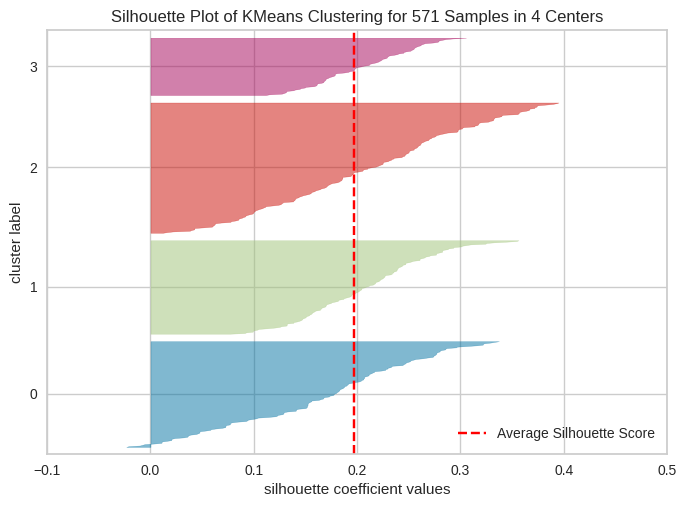

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 571 Samples in 4 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [ ]:
# Silhouette plot and average silhouette score
visualizer_4 = SilhouetteVisualizer(kmeans_4, colors="yellowbrick")
visualizer_4.fit(features_scaled)
print("The average silhouette score is:", visualizer_4.silhouette_score_)
visualizer_4.show()

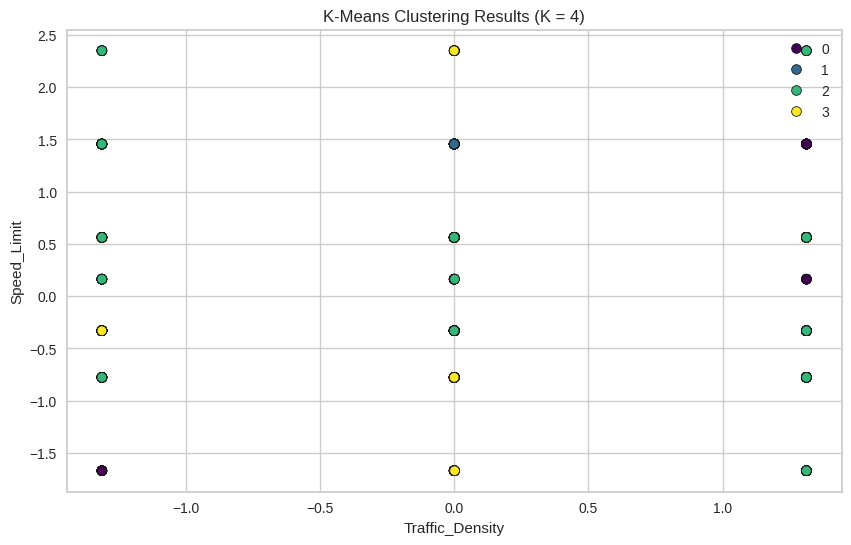

In [ ]:
# Add cluster labels to a copy of the scaled DataFrame for visualization
plot_k4 = features_scaled.copy()
plot_k4['Cluster'] = kmeans_result_4.labels_

# Visualize clustering using a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x=plot_k4.columns[0], y=plot_k4.columns[1], hue='Cluster', data=plot_k4, palette='viridis', edgecolor='k')
plt.title('K-Means Clustering Results (K = 4)')
plt.xlabel(plot_k4.columns[0])
plt.ylabel(plot_k4.columns[1])
plt.legend()
plt.show()

**Interpretation of Results (K = 4):**
* **Average Silhouette Width:** Decreased to `0.1967` (the lowest among the three values). In the Silhouette plot, the clusters become narrower and have lower average scores compared to $K = 3$, which indicates that adding a fourth cluster splits a well-formed group unnecessarily.
* **Total Within-Cluster Sum of Squares (WSS):** Decreased to `2090.0087`. Although WSS continues to decrease as $K$ increases, the reduction is smaller than the drop from $K = 2$ to $K = 3$.
* **Cluster Visualization:** The scatter plot of Traffic_Density versus Speed_Limit shows heavy overlap between the four clusters, because these two attributes do not separate them. According to the cluster centers, Clusters 1 and 3 are the same accident and alcohol groups found with K = 3, while the no-accident, no-alcohol group is split into two clusters by Driver_Experience (≈ +0.92 versus ≈ −0.78). This extra split does not reveal a new pattern.

### Identifying the Optimal Number of Clusters (Best K) Based on Majority Rule

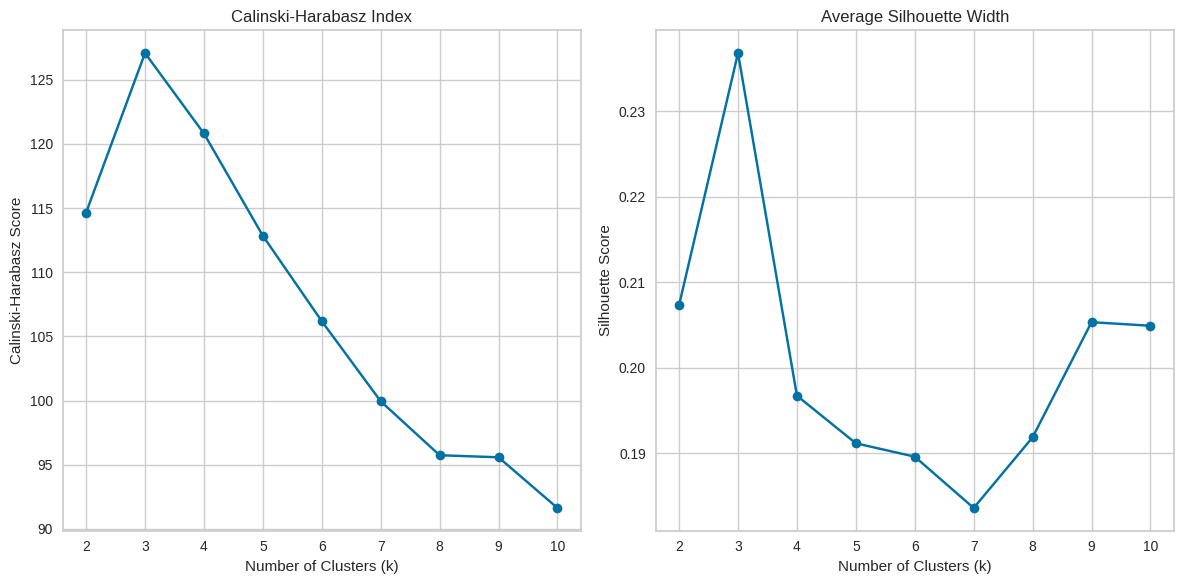

In [ ]:
# Range of clusters to try
k_range = range(2, 11)

# Lists to store scores
ch_scores = []
silhouette_scores = []

# Calculate scores for each value of k
for k in k_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(features_scaled)
    ch_score = calinski_harabasz_score(features_scaled, kmeans.labels_)
    silhouette_avg = silhouette_score(features_scaled, kmeans.labels_)
    ch_scores.append(ch_score)
    silhouette_scores.append(silhouette_avg)

# Plotting results
plt.figure(figsize=(12, 6))

# Plot Calinski-Harabasz Index
plt.subplot(1, 2, 1)
plt.plot(k_range, ch_scores, marker='o')
plt.title('Calinski-Harabasz Index')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Calinski-Harabasz Score')

# Plot Average Silhouette Width
plt.subplot(1, 2, 2)
plt.plot(k_range, silhouette_scores, marker='o')
plt.title('Average Silhouette Width')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

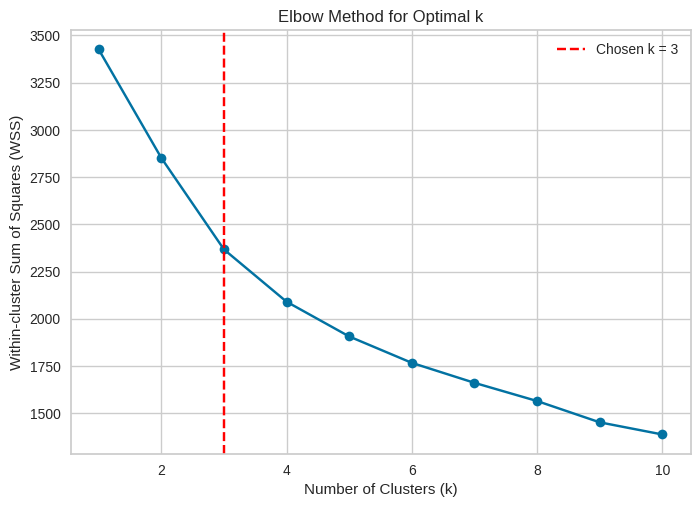

In [ ]:
# Perform k-means clustering for different values of k
wss_values = []
k_values = range(1, 11)

for k in k_values:
    kmeans = make_pipeline(StandardScaler(), KMeans(n_clusters=k, n_init=10, random_state=42))
    kmeans.fit(features_scaled)
    wss_values.append(kmeans.named_steps['kmeans'].inertia_)

# Plot the elbow method
plt.plot(k_values, wss_values, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-cluster Sum of Squares (WSS)')
plt.title('Elbow Method for Optimal k')
plt.axvline(x=3, linestyle='--', color='red', label='Chosen k = 3')
plt.legend()
plt.show()

Based on the **majority rule** across the evaluation methods:
1. **Calinski-Harabasz Index:** Reaches its highest peak at **K = 3**.
2. **Average Silhouette Width:** Achieves the highest score (`0.2368`) at **K = 3** among the values tested from K = 2 to K = 10.
3. **Elbow Method (WSS):** The WSS curve decreases gradually, but its slope changes the most at **K = 3**: the reduction in WSS falls from ≈ 484.55 (K = 2 to K = 3) to ≈ 276.90 (K = 3 to K = 4), and the curve flattens afterwards, so the elbow is located at K = 3.

Since all three evaluation methods agree on K = 3, the optimal number of clusters based on the majority rule is **K = 3**.

### Clustering Evaluation Comparison Table

In [ ]:
clustering_comparison_df = pd.DataFrame(
    {
        'K=2': [round(visualizer_2.silhouette_score_, 4), round(kmeans_result_2.inertia_, 4)],
        'K=3': [round(visualizer_3.silhouette_score_, 4), round(kmeans_result_3.inertia_, 4)],
        'K=4': [round(visualizer_4.silhouette_score_, 4), round(kmeans_result_4.inertia_, 4)]
    },
    index=['Average Silhouette width', 'total within-cluster sum of square']
)

display(clustering_comparison_df)

,K=2,K=3,K=4
Average Silhouette width,0.2073,0.2368,0.1967
total within-cluster sum of square,2851.4522,2366.9052,2090.0087


### Clustering Evaluation Summary

* **Average Silhouette width:** $K = 3$ achieved the highest Silhouette score (`0.2368`) compared to $K = 2$ (`0.2073`) and $K = 4$ (`0.1967`), showing that $K = 3$ produces the most cohesive and well-separated clusters.
* **Total within-cluster sum of square (WSS):** The WSS decreases as K increases, from `2851.4522` at K = 2 to `2366.9052` at K = 3, and `2090.0087` at K = 4. Among the tested values, the largest reduction occurs from K = 2 to K = 3 (≈ 484.55 compared to ≈ 276.90 from K = 3 to K = 4), while moving to K = 4 also reduces the Silhouette width.

# [7] Findings and Discussion

## Classification Findings

The Decision Tree classifier was evaluated using the Gini index and Information Gain (Entropy) across three partitions. As shown in the comparison table, the highest accuracy (**50.00%**) was achieved by the **Entropy model with the 70/30 partition**, so we consider it the best-performing classification model.

**What the final Decision Tree reveals:** The root node of the final tree splits on **Weather**, and the following splits use **Driver_Alcohol** and **Driver_Experience**. This shows that weather, alcohol consumption, and driver experience were the first factors the model used to separate accidents by severity.

**How the classification is achieved:** The tree classifies an accident by following a path of conditions from the root to a leaf. Since the nominal attributes were encoded using "LabelEncoder", the condition "Weather <= 0.5" represents clear weather, and the condition "Driver_Alcohol <= 0.5" represents a driver who did not consume alcohol. For example, under clear weather, if the driver did not consume alcohol, the tree classifies most accidents as **Low** severity. However, under clear weather, if the driver consumed alcohol, the prediction changes to **Moderate** severity. This suggests that alcohol consumption may increase the predicted severity of an accident, although this rule is based on a small group of 26 records. Under other weather conditions, the tree mainly relies on driver experience, and most records are classified as Low severity, which reflects that Low is the most frequent class in the dataset.

Driver_Experience appears several times in the tree because it is a continuous attribute with many distinct values, so the tree can split it at different thresholds. Some of these splits create very small groups (for example, 3 or 9 records), which shows that the tree is trying to separate small groups rather than finding general patterns.

**Are the results meaningful?** The Decision Tree successfully produced clear and interpretable rules, and, as shown in the comparison, Entropy achieved higher accuracy than Gini in two of the three partitions (80/20 and 70/30), including the best overall result. However, the differences between the two measures are small, which suggests that both measures performed similarly on our dataset. The confusion matrices also show an interesting pattern: in five of the six confusion matrices, **Moderate** accidents were most often misclassified as **Low**, which means that the model often confuses the middle severity level with Low. This is similar to the research paper, which found that the middle severity level was the most difficult class to separate. However, the highest accuracy of 50% shows that predicting accident severity using the attributes available in this dataset remains challenging.

## Clustering Findings

Based on the majority rule, the Elbow method, the Silhouette coefficient, and the Calinski-Harabasz index all indicate that **K=3** is the optimal number of clusters, with the highest average Silhouette width (0.2368).

To understand the characteristics of each cluster, we added the cluster labels to the dataset and compared the clusters using the average values of the numerical attributes, the class label, and one of the nominal attributes that were not used in clustering.




In [ ]:
# Add the cluster labels (K=3) to the dataset
df_cluster_raw['Cluster'] = kmeans_result_3.labels_

# Remove the nominal attributes and the class label to keep only the numerical attributes
cluster_data = df_cluster_raw.drop(['Weather', 'Road_Type', 'Time_of_Day', 'Accident_Severity', 'Road_Condition', 'Vehicle_Type', 'Driver_Age', 'Road_Light_Condition'], axis=1)

# Group by the 'Cluster' column and calculate the mean for each numeric column
aggregated_data = cluster_data.groupby('Cluster').mean()
print(aggregated_data)

# Number of records in each cluster
print(df_cluster_raw['Cluster'].value_counts())

         Traffic_Density  Speed_Limit  Number_of_Vehicles  Driver_Alcohol  \
Cluster                                                                     
0               0.485544     0.421518            0.564713             0.0   
1               0.507211     0.415993            0.493653             0.0   
2               0.494147     0.403301            0.502123             1.0   

         Driver_Experience  Accident  
Cluster                               
0                 0.506141  1.000000  
1                 0.496728  0.000000  
2                 0.511358  0.305882  
Cluster
1    348
0    138
2     85
Name: count, dtype: int64


**Cluster characteristics:** The table above shows the average value of each numerical attribute in each cluster, and the number of records in each cluster is shown below the table. Since "Driver_Alcohol" and "Accident" are binary attributes, their average represents the proportion of records with a value of 1:
- **Cluster 0 (138 records):** Records where an accident occurred, with no alcohol involvement.
- **Cluster 1 (348 records):** The largest cluster, containing records with no accident and no alcohol involvement, which represents normal traffic conditions.
- **Cluster 2 (85 records):** Records where the drivers were under the influence of alcohol.

The other attributes (traffic density, speed limit, number of vehicles, and driver experience) have close average values in all clusters.

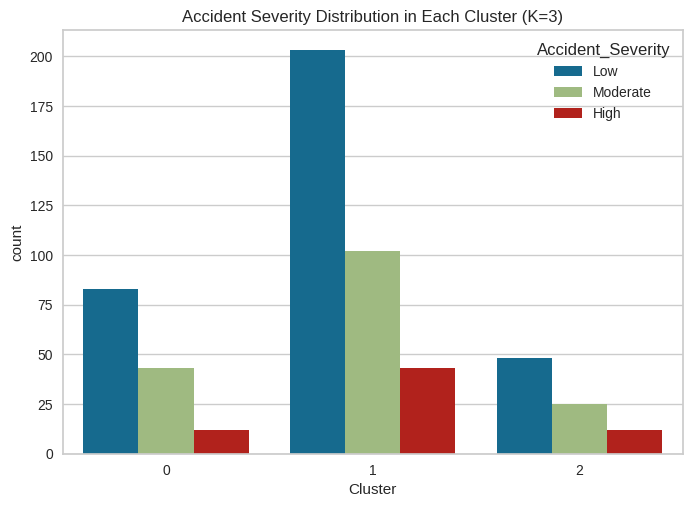

In [ ]:
# Accident severity distribution in each cluster
sns.countplot(x='Cluster', hue='Accident_Severity', data=df_cluster_raw)
plt.title('Accident Severity Distribution in Each Cluster (K=3)')
plt.show()

**Relationship with accident severity:** The plot above shows that Low severity accidents are the most frequent in all three clusters, and the distribution of severity levels follows a similar pattern in each cluster.

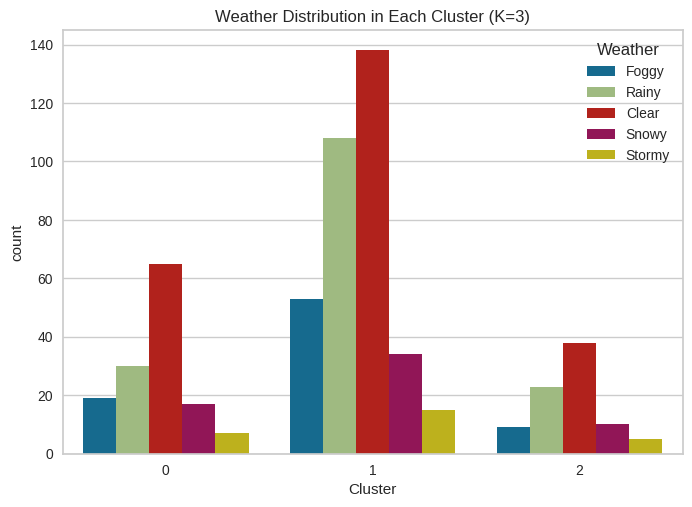

In [ ]:
# Weather distribution in each cluster
sns.countplot(x='Cluster', hue='Weather', data=df_cluster_raw)
plt.title('Weather Distribution in Each Cluster (K=3)')
plt.show()

**Weather distribution:** The plot above shows that the weather conditions are distributed in a similar pattern across the three clusters, which means that weather did not differ between the clusters.


**Is the clustering result meaningful?** Considering all the clustering results above, including the evaluation methods, the table of average values, and the plots, the clustering successfully separated the records into three interpretable groups: accident records, normal traffic records, and alcohol-related records. In addition, all three evaluation methods agreed on K=3, which gives strong support for this choice. However, the other attributes have close average values in all clusters, the severity and weather distributions are similar across the clusters, and the Silhouette width (0.2368) indicates that the clusters are not strongly separated.

## Comparison with the Research Paper

We compared our results with the selected research paper [1], which also classified the severity of traffic incidents into three levels:

- **Best technique:** In the paper, the Decision Tree (C4.5) achieved the best performance among four machine learning methods (Naïve Bayes, SVM, kNN, and Decision Tree), with an F1-score of 0.86 and nearly 90% accuracy. Similarly, we selected the Decision Tree for classification because of its interpretable rules, which the paper also highlighted as its main advantage.
- **Methodology:** The paper compared four different algorithms, while we compared two attribute selection measures (Gini index and Entropy) for the Decision Tree. The paper also evaluated its models using five-fold cross-validation with precision, recall, and F1-score, while we used three training/testing partitions and evaluated the models using accuracy and confusion matrices.
- **Difference in accuracy:** Our best accuracy (50%) is much lower than the paper's results. The main reason is the data: the paper used more than 40,000 real incident records from the NSW Transport Management Centre in Australia, while our preprocessed dataset contains only 571 records.
- **Important attributes:** The paper used 15 attributes including the severity label, which is close to the 14 attributes in our dataset. However, the most important attributes in the paper were directly related to the incident, such as the number of affected lanes, the incident type, the location, and the hour of the day. Our dataset does not include such incident-related attributes.
- **The middle class:** The paper found that the middle severity level was the most difficult class to separate. Our results show a similar pattern, since in most of our confusion matrices, **Moderate** accidents were most often misclassified as **Low**.
- **Outlier removal:** The paper showed that removing outliers improved the performance of the models, which supports our decision to apply noise removal in the preprocessing phase.

Unlike our project, the paper did not apply clustering.

## Conclusion

In this project, we applied classification and clustering to a traffic accident dataset to understand the factors related to accident severity.

- **Best models:** The best classification model was the **Decision Tree using Entropy with the 70/30 partition** (50% accuracy), although the differences between Entropy and Gini were small. The best clustering result was **K-means with K=3** (Silhouette width of 0.2368), which was supported by all three evaluation methods.
- **Information extracted from classification:**
  - Weather, alcohol consumption, and driver experience were the first factors used by the Decision Tree to classify accident severity.
  - Under clear weather, alcohol consumption changed the prediction from Low to Moderate severity, although this rule is based on a small group of 26 records.
  - Moderate accidents were often misclassified as Low.
  - The size of the training set did not have a consistent effect on accuracy, since Gini achieved its best result with the 90/10 partition, while Entropy achieved its best result with the 70/30 partition.
- **Information extracted from clustering:**
  - The clusters were mainly separated by alcohol consumption and accident occurrence, and alcohol-related records formed a separate group.
  - Traffic density, speed limit, number of vehicles, and driver experience had close average values in all clusters, so they did not distinguish the groups.
  - Low severity accidents were the most frequent in all clusters.
  - Increasing K from 3 to 4 reduced the within-cluster sum of squares but also reduced the Silhouette width, which confirms K=3 as the best choice.
- **Problem solution:** The Decision Tree showed that weather, alcohol consumption, and driver experience are the main factors to consider when estimating accident severity, and the clustering showed that alcohol-related records form a separate group. However, since the clusters had similar severity distributions, more data is needed to confirm the effect of these factors on accident severity.
- **Agreement with the research paper:** Like the research paper, our results show that the Decision Tree provides interpretable rules, and that the middle severity level is difficult to classify.
- **Limitations and future work:** The accuracy of the predictions is limited by the size of the dataset and its available attributes. As shown in the research paper, accident severity can be predicted more accurately using a larger dataset with more incident-related attributes, such as the number of affected lanes, the accident location, and the accident type.


# [8] References   

[1] H. Nguyen, C. Cai, and F. Chen, “Automatic classification of traffic incident's severity using machine learning approaches,” *IET Intelligent Transport Systems*, vol. 11, no. 10, pp. 615–623, 2017, doi: [10.1049/iet-its.2017.0051](https://doi.org/10.1049/iet-its.2017.0051).

[2] denkuznetz, “Traffic Accident Prediction 💥🚗,” *Kaggle*. [Online]. Available: https://www.kaggle.com/datasets/denkuznetz/traffic-accident-prediction. [Accessed: Sep. 30, 2026].


